# 07 — Final Model Comparison: Indian AQI Prediction and Forecasting

## Objective

This notebook consolidates the results of the project's completed AQI estimation and forecasting experiments.

Four modelling settings are reviewed:

1. **Model A — Same-day estimation:** Predict AQI using pollutant concentrations from the same day.
2. **Model A — Next-day extension:** Forecast tomorrow's AQI using historical data and current-day information.
3. **Recent-data models:** Predict next-day AQI values and categories using recent AQI observations.
4. **Model B — Cross-period forecasting:** Compare models trained on historical and recent AQI data using identical held-out test observations.

The analysis examines regression and classification performance, improvements over baselines, historical-to-recent transferability, and geographic differences in forecasting errors.

**Methodological principle:** Results from different prediction tasks or test cohorts are reported separately. Direct historical-versus-recent comparisons are restricted to Model B's matched test set.

This notebook loads previously generated results and creates consolidated tables and figures; it does not retrain models.

## 1. Setup, inputs, and reporting folders

Run this notebook from the project root or from `notebooks/`. Paths below match the uploaded source notebooks. If your repository uses different locations, edit the `SOURCES` dictionary.

Missing optional result files are reported explicitly rather than being replaced with invented numbers. No existing generated files are overwritten unless they have the same specific names as this notebook's final report outputs.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name.lower() == 'notebooks':
    ROOT = ROOT.parent

FIGURES = ROOT / 'reports' / 'figures' / 'final_comparison'
RESULTS = ROOT / 'reports' / 'results' / 'final_comparison'
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

SOURCES = {
    'model_a_regression': ROOT / 'outputs' / 'regression_results.csv',
    'model_a_classification': ROOT / 'outputs' / 'classification_results.csv',
    'model_a_next_day': ROOT / 'outputs' / 'next_day_results.csv',
    'recent_regression': ROOT / 'reports' / 'results_regression_2023_25.csv',
    'recent_classification': ROOT / 'reports' / 'results_classification_2023_25.csv',
    'model_b_historical': ROOT / 'reports' / 'results' / 'modelb' / 'historical_model_results.csv',
    'model_b_matched': ROOT / 'reports' / 'results' / 'modelb' / 'all_models_same_test_results.csv',
    'model_b_predictions': ROOT / 'reports' / 'results' / 'modelb' / 'predictions_same_test_rows.csv',
    'model_b_cities': ROOT / 'reports' / 'results' / 'modelb' / 'city_wise_errors.csv',
    'recent_test_predictions': ROOT / 'data' / 'Cleaned' / 'predictions_2023_25_test.csv',
}

print('Repository:', ROOT)
print('Output figures:', FIGURES)
print('Output tables:', RESULTS)
for key, path in SOURCES.items():
    print(f'{"FOUND" if path.is_file() else "MISSING":7} | {key:25} | {path.relative_to(ROOT)}')

Repository: D:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India
Output figures: D:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\reports\figures\final_comparison
Output tables: D:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\reports\results\final_comparison
FOUND   | model_a_regression        | outputs\regression_results.csv
FOUND   | model_a_classification    | outputs\classification_results.csv
FOUND   | model_a_next_day          | outputs\next_day_results.csv
FOUND   | recent_regression         | reports\results_regression_2023_25.csv
FOUND   | recent_classification     | reports\results_classification_2023_25.csv
FOUND   | model_b_historical        | reports\results\modelb\historical_model_results.csv
FOUND   | model_b_matched           | reports\results\modelb\all_models_same_test_results.csv
FOUND   | model_b_predictions       | reports\results\modelb\predictions_same_test_rows.csv
FOUND   | mode

## 2. Load results and inspect schemas

Each modelling notebook exports slightly different metric column names (for example `R2` versus `R²`, or `MacroF1` versus `F1 (macro)`). We normalize only **column labels**, not metric values. Missing values remain missing.

If a CSV is unavailable, rerun the corresponding source notebook and its result-export cell before drawing conclusions.

In [2]:
def read_optional(key):
    path = SOURCES[key]
    if not path.is_file():
        print(f'NOT AVAILABLE: {key} — {path}')
        return None
    try:
        df = pd.read_csv(path)
        if df.empty:
            print(f'EMPTY: {key} — {path}')
            return None
        print(f'Loaded {key}: {len(df)} rows; columns={list(df.columns)}')
        return df
    except Exception as exc:
        print(f'COULD NOT READ {key}: {type(exc).__name__}: {exc}')
        return None

raw = {key: read_optional(key) for key in SOURCES}

def standardized(df, classification=False):
    if df is None:
        return None
    out = df.copy()
    aliases = {
        'model': 'Model', 'MAE': 'MAE', 'RMSE': 'RMSE', 'R2': 'R2',
        'R²': 'R2', 'R^2': 'R2', 'r2': 'R2',
        'Accuracy': 'Accuracy', 'accuracy': 'Accuracy',
        'Precision (macro)': 'MacroPrecision', 'Recall (macro)': 'MacroRecall',
        'F1 (macro)': 'MacroF1', 'MacroF1': 'MacroF1',
        'macro_f1': 'MacroF1', 'Macro Precision': 'MacroPrecision',
        'Macro Recall': 'MacroRecall'
    }
    out = out.rename(columns={k:v for k,v in aliases.items() if k in out.columns})
    if 'Model' not in out.columns:
        print('WARNING: Missing Model column; cannot make model-level comparison')
        return None
    for col in (['Accuracy','MacroPrecision','MacroRecall','MacroF1'] if classification else ['MAE','RMSE','R2']):
        if col not in out.columns:
            out[col] = np.nan
        out[col] = pd.to_numeric(out[col], errors='coerce')
    return out

experiment_specs = [
    ('Model A — same-day AQI', 'model_a_regression', 'Same-day AQI estimation', False),
    ('Model A — next-day AQI', 'model_a_next_day', 'Next-day AQI forecast', False),
    ('Recent — next-day AQI', 'recent_regression', 'Next-day AQI forecast', False),
    ('Model B — cross-period', 'model_b_matched', 'Next-day AQI forecast (matched recent test)', False),
]
all_reg = []
for label, key, task, _ in experiment_specs:
    frame = standardized(raw[key])
    if frame is not None:
        frame['Experiment'] = label
        frame['Task'] = task
        all_reg.append(frame)
regression = pd.concat(all_reg, ignore_index=True, sort=False) if all_reg else pd.DataFrame()
if not regression.empty:
    cols = ['Experiment','Model','Task','Training','MAE','RMSE','R2']
    display(regression[[c for c in cols if c in regression.columns]].round(3))
else:
    print('No regression files could be loaded.')

Loaded model_a_regression: 4 rows; columns=['Model', 'MAE', 'RMSE', 'R2']
Loaded model_a_classification: 4 rows; columns=['Model', 'Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)']
Loaded model_a_next_day: 3 rows; columns=['Model', 'MAE', 'RMSE', 'R2']
Loaded recent_regression: 6 rows; columns=['Model', 'MAE', 'RMSE', 'R2']
Loaded recent_classification: 6 rows; columns=['Model', 'Accuracy', 'MacroF1', 'MacroPrecision', 'MacroRecall']
Loaded model_b_historical: 4 rows; columns=['Training', 'Model', 'MAE', 'RMSE', 'R2']
Loaded model_b_matched: 7 rows; columns=['Training', 'Model', 'MAE', 'RMSE', 'R2']
Loaded model_b_predictions: 3604 rows; columns=['City', 'Date', 'target_date', 'actual', 'Persistence', 'Historical - Ridge Regression', 'Historical - Random Forest', 'Historical - Hist Gradient Boosting', 'Recent - Ridge Regression', 'Recent - Random Forest', 'Recent - Hist Gradient Boosting']
Loaded model_b_cities: 23 rows; columns=['City', 'n', 'Historical_MAE', 'Persisten

,Experiment,Model,Task,Training,MAE,RMSE,R2
0,Model A — same-day AQI,Baseline (predict mean),Same-day AQI estimation,NaN,102.224,130.034,-0.169
1,Model A — same-day AQI,Linear Regression,Same-day AQI estimation,NaN,27.802,45.866,0.855
2,Model A — same-day AQI,Decision Tree,Same-day AQI estimation,NaN,23.812,50.536,0.823
3,Model A — same-day AQI,Random Forest,Same-day AQI estimation,NaN,19.961,41.165,0.883
4,Model A — next-day AQI,Persistence (tomorrow = today),Next-day AQI forecast,NaN,26.242,59.867,0.744
5,Model A — next-day AQI,Linear Regression,Next-day AQI forecast,NaN,25.657,48.565,0.832
6,Model A — next-day AQI,Random Forest,Next-day AQI forecast,NaN,22.727,48.193,0.834
7,Recent — next-day AQI,Hist Gradient Boosting,Next-day AQI forecast,NaN,23.505,33.854,0.728
8,Recent — next-day AQI,Hist Gradient Boosting (tuned),Next-day AQI forecast,NaN,23.508,33.858,0.728
9,Recent — next-day AQI,Random Forest,Next-day AQI forecast,NaN,23.531,33.976,0.726


## 3. Model A — Same-Day Pollutant-Based AQI Estimation

Model A estimates same-day AQI from pollutant measurements using historical city-level observations.

Random Forest achieves the strongest reported regression performance:

- **MAE:** 19.961
- **RMSE:** 41.165
- **R²:** 0.883

This substantially improves upon the mean-prediction baseline MAE of **102.224**. Decision Tree and Linear Regression achieve MAE values of **23.812** and **27.802**, respectively.

Because AQI is calculated from pollutant measurements, strong same-day estimation performance does not imply equivalent next-day forecasting accuracy.

These results are evaluated only within Model A's original test cohort.

,Model,MAE,RMSE,R2
3,Random Forest,19.961,41.165,0.883
2,Decision Tree,23.812,50.536,0.823
1,Linear Regression,27.802,45.866,0.855
0,Baseline (predict mean),102.224,130.034,-0.169


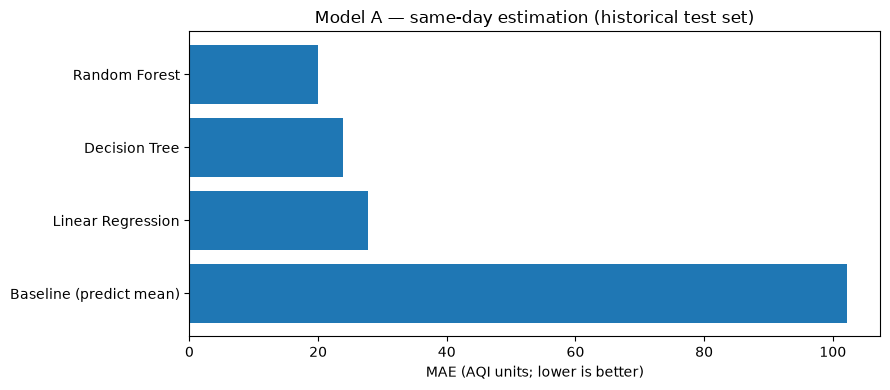

In [3]:
model_a = standardized(raw['model_a_regression'])
if model_a is not None:
    display(model_a[['Model','MAE','RMSE','R2']].sort_values('MAE').round(3))
    fig, ax = plt.subplots(figsize=(9,4))
    ordered = model_a.sort_values('MAE', ascending=False)
    ax.barh(ordered['Model'], ordered['MAE'])
    ax.set(xlabel='MAE (AQI units; lower is better)', title='Model A — same-day estimation (historical test set)')
    fig.tight_layout()
    fig.savefig(FIGURES/'model_a_same_day_mae.png', dpi=160, bbox_inches='tight')
    plt.show()
else:
    print("Run Aditri's 02_regression.ipynb to generate outputs/regression_results.csv.")

## 4. Next-Day AQI Forecasting

Two independently evaluated next-day forecasting approaches are reviewed.

### Model A — Historical Next-Day Extension

Random Forest achieves the lowest MAE (**22.727**), improving upon its persistence baseline (**26.242**). Linear Regression achieves an MAE of **25.657**.

This experiment uses historical data and current-day pollutant information, assuming these measurements are available when generating the next-day forecast.

### Recent-Data Forecasting

Histogram Gradient Boosting achieves the lowest MAE (**23.505**), compared with **24.783** for persistence, representing an improvement of approximately **5.2%**.

Random Forest (**23.531**) and Ridge Regression (**23.614**) achieve similar performance, while tuning Histogram Gradient Boosting produces no meaningful improvement.

**Comparison boundary:** Although both experiments predict next-day AQI, their input features and test observations differ. Their MAE values must not be interpreted as a direct ranking between the two approaches.


Model A — historical next-day


,Model,MAE,RMSE,R2
2,Random Forest,22.727,48.193,0.834
1,Linear Regression,25.657,48.565,0.832
0,Persistence (tomorrow = today),26.242,59.867,0.744


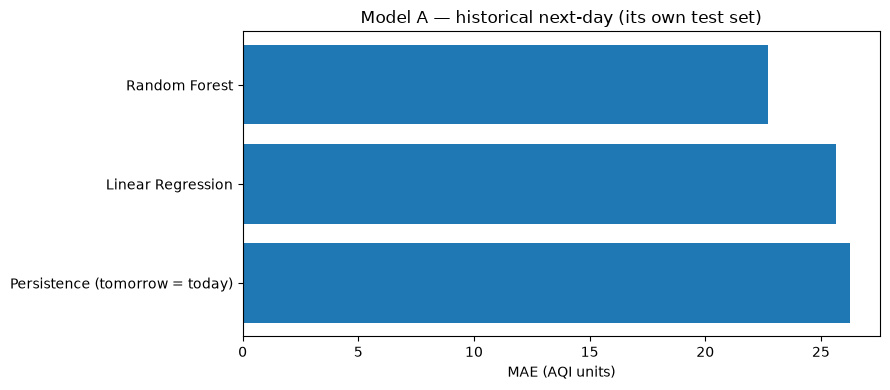


Recent — next-day


,Model,MAE,RMSE,R2
0,Hist Gradient Boosting,23.505,33.854,0.728
1,Hist Gradient Boosting (tuned),23.508,33.858,0.728
2,Random Forest,23.531,33.976,0.726
3,Ridge Regression,23.614,33.918,0.727
4,Baseline: tomorrow = today,24.783,37.158,0.672
5,Baseline: 7-day mean,30.651,43.397,0.553


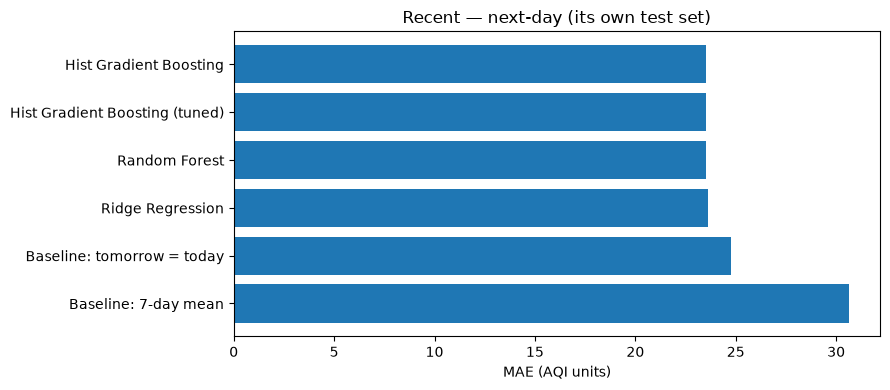

In [4]:
next_day_frames = [
    ('Model A — historical next-day', standardized(raw['model_a_next_day'])),
    ('Recent — next-day', standardized(raw['recent_regression'])),
]
for title, frame in next_day_frames:
    print('\n' + title)
    if frame is None:
        print('Result file unavailable.')
        continue
    display(frame[['Model','MAE','RMSE','R2']].sort_values('MAE').round(3))
    fig, ax = plt.subplots(figsize=(9, 4))
    plot = frame.sort_values('MAE', ascending=False)
    ax.barh(plot['Model'], plot['MAE'])
    ax.set(xlabel='MAE (AQI units)', title=title + ' (its own test set)')
    fig.tight_layout()
    slug = 'model_a_next_day' if title.startswith('Model A') else 'recent_next_day'
    fig.savefig(FIGURES/f'{slug}_mae.png', dpi=160, bbox_inches='tight')
    plt.show()

## 5. AQI Category Classification

Classification performance is evaluated using accuracy, macro-precision, macro-recall, and macro-F1 to account for imbalanced air-quality categories.

### Model A — Same-Day Classification

Random Forest is the strongest reported classifier:

- **Accuracy:** 76.9%
- **Macro-F1:** 0.691

The majority-class baseline achieves **34.6% accuracy** and **0.086 macro-F1**.

### Recent-Data Next-Day Classification

The persistence baseline achieves **70.7% accuracy** and **0.592 macro-F1**, outperforming the trained classifiers.

Random Forest is the strongest trained classifier, with **69.3% accuracy** and **0.584 macro-F1**. The tuned Histogram Gradient Boosting model also achieves approximately **0.584 macro-F1**.

The results highlight the difficulty of improving next-day category predictions beyond current-day AQI persistence. Rare high-pollution categories also remain challenging.

Same-day and next-day classification results are reported separately because their targets and evaluation conditions differ.


Model A — same-day classification


,Model,Accuracy,MacroPrecision,MacroRecall,MacroF1
3,Random Forest,0.769,0.778,0.671,0.691
2,Decision Tree,0.732,0.717,0.666,0.681
1,Logistic Regression,0.719,0.666,0.638,0.644
0,Baseline (most frequent),0.346,0.058,0.167,0.086


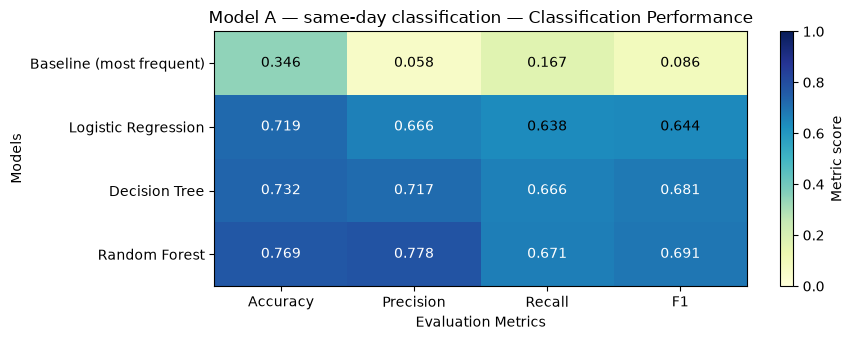

Saved: D:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\reports\figures\final_comparison\model_a_classification_classification_heatmap.png

Recent — next-day classification


,Model,Accuracy,MacroPrecision,MacroRecall,MacroF1
0,Baseline: tomorrow = today,0.707,0.590,0.594,0.592
1,Random Forest,0.693,0.567,0.614,0.584
2,Hist Gradient Boosting (tuned),0.683,0.556,0.636,0.584
3,Hist Gradient Boosting,0.683,0.550,0.629,0.577
4,Logistic Regression,0.671,0.501,0.649,0.538
5,Baseline: always 'Satisfactory',0.330,0.055,0.167,0.083


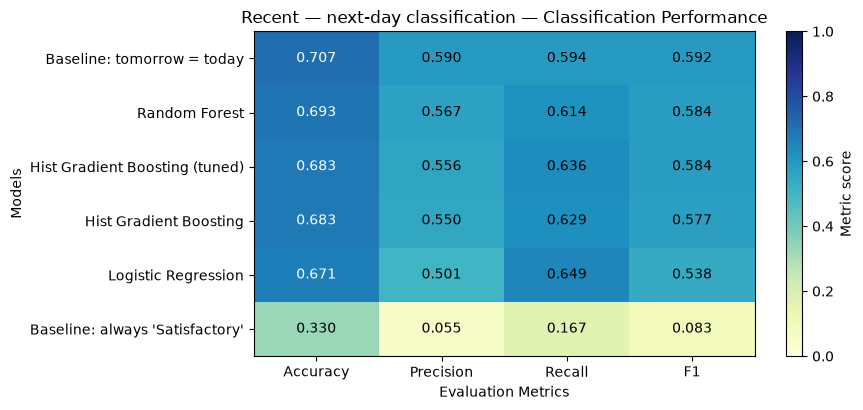

Saved: D:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\reports\figures\final_comparison\recent_classification_classification_heatmap.png


In [5]:
# Section 5 — Classification comparison heatmaps

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIGURES.mkdir(parents=True, exist_ok=True)

class_specs = [
    ('Model A — same-day classification', 'model_a_classification'),
    ('Recent — next-day classification', 'recent_classification'),
]

classification_frames = []

for label, key in class_specs:

    frame = standardized(raw[key], classification=True)

    print('\n' + label)

    if frame is None or frame.empty:
        print('Results unavailable')
        continue

    frame = frame.copy()
    frame['Experiment'] = label
    classification_frames.append(frame)

    metrics = [
        'Accuracy',
        'MacroPrecision',
        'MacroRecall',
        'MacroF1'
    ]

    # Display classification results
    display(
        frame[['Model'] + metrics]
        .sort_values('MacroF1', ascending=False)
        .round(3)
    )

    # Prepare heatmap
    heat = frame.set_index('Model')[metrics]
    heat = heat.apply(pd.to_numeric, errors='coerce')

    fig, ax = plt.subplots(
        figsize=(9, max(3.5, len(heat) * 0.7))
    )

    values = heat.to_numpy(dtype=float)

    im = ax.imshow(
        values,
        cmap='YlGnBu',
        vmin=0,
        vmax=1,
        aspect='auto'
    )

    ax.set_xticks(range(len(metrics)))
    ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1'])

    ax.set_yticks(range(len(heat)))
    ax.set_yticklabels(heat.index)

    # Add metric values
    for i in range(len(heat)):
        for j in range(len(metrics)):
            value = values[i, j]

            if np.isfinite(value):
                ax.text(
                    j, i, f'{value:.3f}',
                    ha='center',
                    va='center',
                    color='white' if value >= 0.65 else 'black'
                )

    ax.set_title(f'{label} — Classification Performance')
    ax.set_xlabel('Evaluation Metrics')
    ax.set_ylabel('Models')

    fig.colorbar(im, ax=ax, label='Metric score')

    fig.tight_layout()

    save_path = FIGURES / f'{key}_classification_heatmap.png'

    fig.savefig(
        save_path,
        dpi=160,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)

    print('Saved:', save_path)

# Combine results for later sections
if classification_frames:
    final_classification = pd.concat(
        classification_frames,
        ignore_index=True
    )
else:
    final_classification = pd.DataFrame()

## 6. Model B — Historical Versus Recent Training

Model B evaluates cross-period forecasting performance on the **same 3,604 held-out observations across 23 cities**, with target dates from November 2024 to April 2025.

All models use the same AQI-based feature schema, allowing historical and recent training strategies to be compared within the matched evaluation cohort.

| Model | Historical MAE | Recent MAE |
|---|---:|---:|
| Ridge Regression | 23.336 | 23.090 |
| Random Forest | 23.458 | 23.532 |
| Histogram Gradient Boosting | 23.210 | 23.313 |

The persistence baseline achieves an MAE of **24.270**.

Recent-trained Ridge Regression produces the lowest overall MAE (**23.090**). Historical-trained Histogram Gradient Boosting and Random Forest slightly outperform their recent-trained counterparts.

The MAE differences are small and do not show a consistent advantage for either training period.

Notebook 06B independently checks the temporal alignment, prediction integrity, and reproducibility of these results.

,Model,Training,MAE,RMSE,R2
0,Hist Gradient Boosting,Historical 2015–2020,23.210,33.363,0.800
1,Hist Gradient Boosting,Recent pre-test (2023–2024),23.313,33.660,0.796
2,Persistence (tomorrow = today),No fitting,24.270,35.826,0.769
3,Random Forest,Historical 2015–2020,23.458,33.569,0.797
4,Random Forest,Recent pre-test (2023–2024),23.532,33.935,0.793
5,Ridge Regression,Historical 2015–2020,23.336,33.477,0.798
6,Ridge Regression,Recent pre-test (2023–2024),23.090,33.119,0.802


Training,Historical 2015–2020,Recent pre-test (2023–2024)
Model,,
Hist Gradient Boosting,23.210,23.313
Random Forest,23.458,23.532
Ridge Regression,23.336,23.090


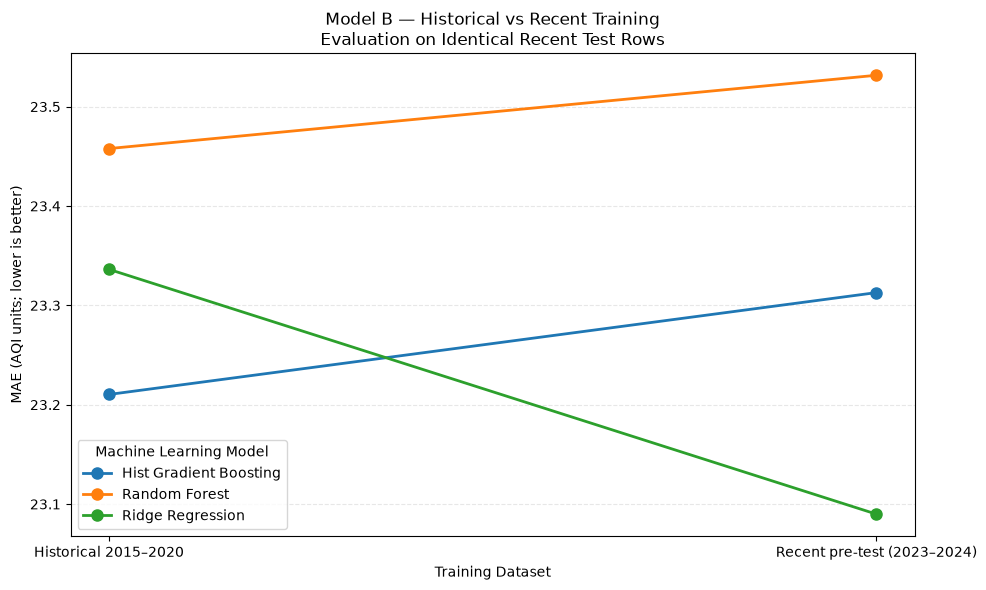

Slope chart saved to: D:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\reports\figures\final_comparison\model_b_training_slope.png

MAE comparison between training cohorts:


Training,Historical 2015–2020,Recent pre-test (2023–2024),MAE_Difference
Model,,,
Hist Gradient Boosting,23.210,23.313,0.103
Random Forest,23.458,23.532,0.074
Ridge Regression,23.336,23.090,-0.246



Negative difference means the second training cohort has lower MAE.


In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIGURES.mkdir(parents=True, exist_ok=True)

# Load and standardize Model B matched results
matched = standardized(raw['model_b_matched'])

if matched is None or matched.empty:
    print(
        'Model B matched results missing; '
        'run notebook 06 through its comparison/export cell.'
    )

elif 'Training' not in matched.columns:
    print(
        'WARNING: Model B results must include a '
        'Training column to identify cohorts.'
    )

else:
    

    display(
        matched[
            ['Model', 'Training', 'MAE', 'RMSE', 'R2']
        ]
        .sort_values(['Model', 'Training'])
        .round(3)
    )



    train_only = matched[
        matched['Training']
        .astype(str)
        .str.lower()
        .ne('no fitting')
    ].copy()

  

    paired = train_only.pivot_table(
        index='Model',
        columns='Training',
        values='MAE',
        aggfunc='first'
    )

    if len(paired.columns) >= 2:

        display(paired.round(3))

   

        cohorts = list(paired.columns)

        fig, ax = plt.subplots(figsize=(10, 6))

        for model, row in paired.iterrows():

            if row.notna().sum() < 2:
                continue

            ax.plot(
                range(len(cohorts)),
                row[cohorts].to_numpy(dtype=float),
                marker='o',
                markersize=8,
                linewidth=2,
                label=model
            )

        ax.set_xticks(range(len(cohorts)))
        ax.set_xticklabels(cohorts)

        ax.set_ylabel(
            'MAE (AQI units; lower is better)'
        )

        ax.set_xlabel('Training Dataset')

        ax.set_title(
            'Model B — Historical vs Recent Training\n'
            'Evaluation on Identical Recent Test Rows'
        )

        ax.legend(
            title='Machine Learning Model',
            loc='best'
        )

        ax.grid(
            axis='y',
            linestyle='--',
            alpha=0.3
        )

        fig.tight_layout()

    

        save_path = (
            FIGURES / 'model_b_training_slope.png'
        )

        fig.savefig(
            save_path,
            dpi=160,
            bbox_inches='tight'
        )

        plt.show()
        plt.close(fig)

        print('Slope chart saved to:', save_path)

   
        if len(cohorts) == 2:

            difference = paired.copy()

            difference['MAE_Difference'] = (
                difference[cohorts[1]]
                - difference[cohorts[0]]
            )

            print('\nMAE comparison between training cohorts:')

            display(difference.round(3))

            print(
                '\nNegative difference means the second '
                'training cohort has lower MAE.'
            )

    else:
        print(
            'Need at least two training cohorts '
            'for a paired comparison.'
        )

## 7. Focus-City Forecasting Comparison

Model B predictions are evaluated separately for **Delhi, Chandigarh, and Mumbai**, using **175 matched test observations per city**.

The following table reports the lowest MAE among the six trained models for each city, alongside persistence.

| City | Best Model | Model MAE | Persistence MAE |
|---|---|---:|---:|
| Delhi | Historical Histogram Gradient Boosting | 34.21 | 35.75 |
| Chandigarh | Historical Ridge Regression | 29.34 | 31.35 |
| Mumbai | Historical Ridge Regression | 12.96 | 14.31 |

Delhi records the highest absolute forecasting error among the three cities, while Mumbai records the lowest.

Each city's best reported model improves upon persistence. However, these city-specific results select the lowest test MAE and should be interpreted as descriptive comparisons rather than independent model-selection results.

Differences in AQI levels, variability, and local pollution episodes may contribute to the observed error patterns, but causal explanations cannot be established from these results alone.

Available focus cities: ['Delhi', 'Chandigarh', 'Mumbai']
Missing focus cities: []

City-wise Model B Forecasting Results:


,City,Model,n,MAE
8,Chandigarh,Historical - Ridge Regression,175,29.34
12,Chandigarh,Recent - Random Forest,175,29.61
11,Chandigarh,Recent - Ridge Regression,175,29.65
9,Chandigarh,Historical - Random Forest,175,29.80
10,Chandigarh,Historical - Hist Gradient Boosting,175,29.80
13,Chandigarh,Recent - Hist Gradient Boosting,175,30.12
7,Chandigarh,Persistence,175,31.35
3,Delhi,Historical - Hist Gradient Boosting,175,34.21
1,Delhi,Historical - Ridge Regression,175,34.82
4,Delhi,Recent - Ridge Regression,175,35.14


CSV saved to: D:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\reports\results\final_comparison\focus_city_model_b_metrics.csv


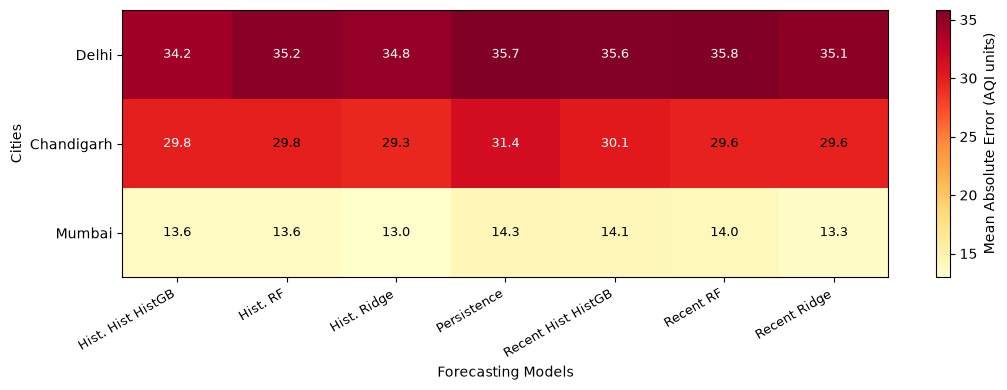

Heatmap saved to: D:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\reports\figures\final_comparison\focus_cities_model_b_heatmap.png


In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error

FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)



pred = raw['model_b_predictions']

if pred is not None and {'City', 'actual'}.issubset(pred.columns):

    pred = pred.copy()

    # Standardize city names
    pred['City'] = (
        pred['City']
        .astype(str)
        .str.strip()
        .replace({
            'New Delhi': 'Delhi',
            'Bangalore': 'Bengaluru',
            'Gurgaon': 'Gurugram'
        })
    )

    # Cities to compare
    choices = ['Delhi', 'Chandigarh', 'Mumbai']

    present = [
        city for city in choices
        if city in set(pred['City'])
    ]

    missing = sorted(set(choices) - set(present))

    print("Available focus cities:", present)
    print("Missing focus cities:", missing)



    prediction_cols = [
        col for col in pred.columns
        if (
            col == 'Persistence'
            or col.startswith('Historical - ')
            or col.startswith('Recent - ')
        )
    ]

    if prediction_cols and present:



        score_rows = []

        for city in present:

            subset = pred[pred['City'] == city].copy()

            for col in prediction_cols:

                actual = pd.to_numeric(
                    subset['actual'],
                    errors='coerce'
                )

                predicted = pd.to_numeric(
                    subset[col],
                    errors='coerce'
                )

                valid = actual.notna() & predicted.notna()

                if valid.any():

                    mae = mean_absolute_error(
                        actual[valid],
                        predicted[valid]
                    )

                    score_rows.append({
                        'City': city,
                        'Model': col,
                        'n': int(valid.sum()),
                        'MAE': mae
                    })

        cities = pd.DataFrame(score_rows)

        if not cities.empty:



            print("\nCity-wise Model B Forecasting Results:")

            display(
                cities
                .sort_values(['City', 'MAE'])
                .round(2)
            )

            # Save results CSV
            csv_path = (
                RESULTS / 'focus_city_model_b_metrics.csv'
            )

            cities.to_csv(
                csv_path,
                index=False
            )

            print("CSV saved to:", csv_path)

       

            pivot = cities.pivot_table(
                index='City',
                columns='Model',
                values='MAE',
                aggfunc='first'
            )

            # Preserve requested city order
            pivot = pivot.reindex(
                [city for city in choices if city in pivot.index]
            )

            values = pivot.to_numpy(dtype=float)

   

            fig, ax = plt.subplots(
                figsize=(
                    max(11, len(pivot.columns) * 1.3),
                    max(4, len(pivot.index) * 0.9)
                )
            )

            im = ax.imshow(
                values,
                cmap='YlOrRd',
                aspect='auto'
            )

            # X-axis: models
            ax.set_xticks(range(len(pivot.columns)))

            ax.set_xticklabels(
                pivot.columns,
                rotation=45,
                ha='right'
            )

            # Y-axis: cities
            ax.set_yticks(range(len(pivot.index)))
            ax.set_yticklabels(pivot.index)

            finite_values = values[np.isfinite(values)]

            midpoint = (
                np.median(finite_values)
                if len(finite_values)
                else 0
            )

            for i in range(values.shape[0]):
                for j in range(values.shape[1]):

                    value = values[i, j]

                    if np.isfinite(value):

                        ax.text(
                            j,
                            i,
                            f'{value:.1f}',
                            ha='center',
                            va='center',
                            fontsize=9,
                            color=(
                                'white'
                                if value > midpoint
                                else 'black'
                            )
                        )

    

            short_names = (
               pivot.columns
               .str.replace('Historical - ', 'Hist. ', regex=False)
               .str.replace('Recent - ', 'Recent ', regex=False)
               .str.replace('Gradient Boosting', 'HistGB', regex=False)
               .str.replace('Random Forest', 'RF', regex=False)
               .str.replace('Ridge Regression', 'Ridge', regex=False)
)

            ax.set_xticklabels(
                 short_names,
                 rotation=30,
                 ha='right',
                 fontsize=9
)

            ax.set_xlabel('Forecasting Models')
            ax.set_ylabel('Cities')

            colorbar = fig.colorbar(
                im,
                ax=ax
            )

            colorbar.set_label(
                'Mean Absolute Error (AQI units)'
            )

            fig.tight_layout()

         

            save_path = (
                FIGURES / 'focus_cities_model_b_heatmap.png'
            )

            fig.savefig(
                save_path,
                dpi=160,
                bbox_inches='tight'
            )

            plt.show()
            plt.close(fig)

            print("Heatmap saved to:", save_path)

        else:
            print("No valid city-level predictions available.")

    elif not present:
        print("None of the selected cities is available.")

    else:
        print(
            "No prediction-model columns found. "
            "Available columns:",
            list(pred.columns)
        )

else:
    print(
        "City-level matched predictions are missing "
        "or do not contain City and actual columns."
    )

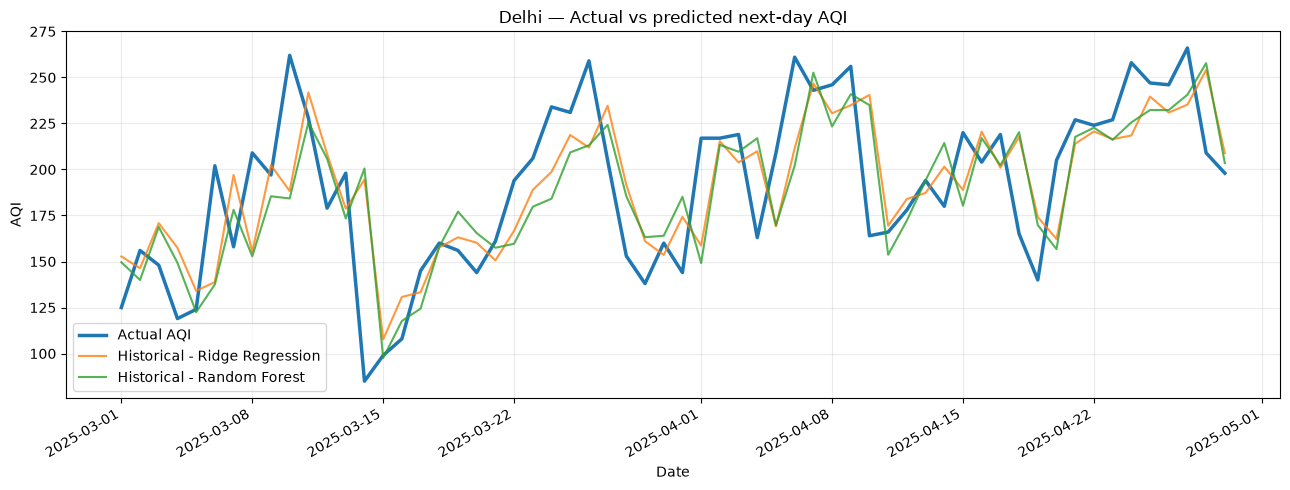

In [8]:
# Actual vs predicted AQI for one focus city
if pred is not None and 'Date' in pred.columns:
    city = 'Delhi'
    city_df = pred[pred['City'] == city].copy()
    city_df['Date'] = pd.to_datetime(city_df['Date'], errors='coerce')

    city_df = city_df.dropna(subset=['Date']).sort_values('Date')

    model_cols = [
        c for c in city_df.columns
        if c.startswith('Historical - ') or c.startswith('Recent - ')
    ]

    if not city_df.empty and model_cols:
        fig, ax = plt.subplots(figsize=(13, 5))

        # Last 60 available observations for readability
        sample = city_df.tail(60)

        ax.plot(sample['Date'], sample['actual'],
                label='Actual AQI', linewidth=2.5)

        for col in model_cols[:2]:
            ax.plot(sample['Date'], sample[col],
                    label=col, alpha=0.8)

        ax.set_title(f'{city} — Actual vs predicted next-day AQI')
        ax.set_xlabel('Date')
        ax.set_ylabel('AQI')
        ax.legend()
        ax.grid(alpha=0.25)

        fig.autofmt_xdate()
        fig.tight_layout()
        fig.savefig(
            FIGURES / 'delhi_actual_vs_predicted.png',
            dpi=160, bbox_inches='tight'
        )
        plt.show()
    else:
        print('Delhi predictions or suitable model columns unavailable.')
else:
    print('No Date column available for time-series plotting.')

## 8. Summary tables (with comparison boundaries)

These tables collect all available metrics for the report. **Do not sort the combined regression table into a single "best overall" ranking.** Different tasks, targets, feature availability, and test observations make such a leaderboard invalid.

The one legitimate across-training-period comparison is Model B's matched-test table, subject to validation in notebook 06b.

In [12]:
# ============================================================
# SECTION 8 — EXPORT FINAL COMPARISON RESULTS
# ============================================================

# 1. Export regression summary
if not regression.empty:
    reg_cols = [
        'Experiment', 'Task', 'Model',
        'Training', 'MAE', 'RMSE', 'R2'
    ]

    reg_summary = regression[
        [c for c in reg_cols if c in regression.columns]
    ].copy()

    reg_summary.to_csv(
        RESULTS / 'final_regression_summary.csv',
        index=False
    )

    display(reg_summary.round(3))

    print('Saved:', RESULTS / 'final_regression_summary.csv')


# 2. Export classification summary
if not final_classification.empty:
    clf_cols = [
        'Experiment', 'Model', 'Accuracy',
        'MacroPrecision', 'MacroRecall', 'MacroF1'
    ]

    clf_summary = final_classification[
        [c for c in clf_cols if c in final_classification.columns]
    ].copy()

    clf_summary.to_csv(
        RESULTS / 'final_classification_summary.csv',
        index=False
    )

    display(clf_summary.round(3))

    print('Saved:', RESULTS / 'final_classification_summary.csv')


# 3. Export source availability
availability = pd.DataFrame([
    {
        'Result_file': k,
        'Available': raw[k] is not None,
        'Path': str(v.relative_to(ROOT))
    }
    for k, v in SOURCES.items()
])

availability.to_csv(
    RESULTS / 'source_availability.csv',
    index=False
)

display(availability)

,Experiment,Task,Model,Training,MAE,RMSE,R2
0,Model A — same-day AQI,Same-day AQI estimation,Baseline (predict mean),NaN,102.224,130.034,-0.169
1,Model A — same-day AQI,Same-day AQI estimation,Linear Regression,NaN,27.802,45.866,0.855
2,Model A — same-day AQI,Same-day AQI estimation,Decision Tree,NaN,23.812,50.536,0.823
3,Model A — same-day AQI,Same-day AQI estimation,Random Forest,NaN,19.961,41.165,0.883
4,Model A — next-day AQI,Next-day AQI forecast,Persistence (tomorrow = today),NaN,26.242,59.867,0.744
5,Model A — next-day AQI,Next-day AQI forecast,Linear Regression,NaN,25.657,48.565,0.832
6,Model A — next-day AQI,Next-day AQI forecast,Random Forest,NaN,22.727,48.193,0.834
7,Recent — next-day AQI,Next-day AQI forecast,Hist Gradient Boosting,NaN,23.505,33.854,0.728
8,Recent — next-day AQI,Next-day AQI forecast,Hist Gradient Boosting (tuned),NaN,23.508,33.858,0.728
9,Recent — next-day AQI,Next-day AQI forecast,Random Forest,NaN,23.531,33.976,0.726


Saved: D:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\reports\results\final_comparison\final_regression_summary.csv


,Experiment,Model,Accuracy,MacroPrecision,MacroRecall,MacroF1
0,Model A — same-day classification,Baseline (most frequent),0.346,0.058,0.167,0.086
1,Model A — same-day classification,Logistic Regression,0.719,0.666,0.638,0.644
2,Model A — same-day classification,Decision Tree,0.732,0.717,0.666,0.681
3,Model A — same-day classification,Random Forest,0.769,0.778,0.671,0.691
4,Recent — next-day classification,Baseline: tomorrow = today,0.707,0.590,0.594,0.592
5,Recent — next-day classification,Random Forest,0.693,0.567,0.614,0.584
6,Recent — next-day classification,Hist Gradient Boosting (tuned),0.683,0.556,0.636,0.584
7,Recent — next-day classification,Hist Gradient Boosting,0.683,0.550,0.629,0.577
8,Recent — next-day classification,Logistic Regression,0.671,0.501,0.649,0.538
9,Recent — next-day classification,Baseline: always 'Satisfactory',0.330,0.055,0.167,0.083


Saved: D:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\reports\results\final_comparison\final_classification_summary.csv


,Result_file,Available,Path
0,model_a_regression,True,outputs\regression_results.csv
1,model_a_classification,True,outputs\classification_results.csv
2,model_a_next_day,True,outputs\next_day_results.csv
3,recent_regression,True,reports\results_regression_2023_25.csv
4,recent_classification,True,reports\results_classification_2023_25.csv
5,model_b_historical,True,reports\results\modelb\historical_model_result...
6,model_b_matched,True,reports\results\modelb\all_models_same_test_re...
7,model_b_predictions,True,reports\results\modelb\predictions_same_test_r...
8,model_b_cities,True,reports\results\modelb\city_wise_errors.csv
9,recent_test_predictions,True,data\Cleaned\predictions_2023_25_test.csv


## 9. Integrated Findings and Interpretation

The project investigates both pollutant-based AQI estimation and next-day AQI forecasting across historical and recent Indian air-quality observations.

### Key Findings

1. **Same-day AQI estimation:** Model A's Random Forest achieves an MAE of **19.961** and R² of **0.883**, substantially outperforming its mean-prediction baseline. This result concerns same-day estimation rather than forecasting.

2. **Historical next-day forecasting:** Model A's Random Forest extension achieves an MAE of **22.727**, improving upon its own persistence baseline of **26.242**.

3. **Recent next-day regression:** Histogram Gradient Boosting achieves an MAE of **23.505**, representing an approximately **5.2% improvement** over persistence.

4. **Recent next-day classification:** Persistence achieves **0.592 macro-F1** and **70.7% accuracy**, outperforming the trained classification models on both metrics.

5. **Cross-period generalization:** Historical-trained models remain competitive on recent observations. On Model B's matched test set, historical Histogram Gradient Boosting achieves an MAE of **23.210**, while recent-trained Ridge Regression achieves **23.090**.

6. **Training-period effects:** Historical training slightly benefits Histogram Gradient Boosting and Random Forest, while recent training benefits Ridge Regression. No consistent advantage is observed across all model families.

7. **Geographic variation:** Among Delhi, Chandigarh, and Mumbai, forecasting errors are highest in Delhi and lowest in Mumbai on the matched Model B evaluation cohort.

### Interpretation

The findings demonstrate strong temporal persistence in daily AQI and modest improvements from machine-learning regression models. Historical AQI observations retain predictive value for recent forecasting, although improvements vary by algorithm.

The strongest methodological conclusion is that AQI estimation, next-day prediction, and cross-period transfer must be assessed within their respective evaluation settings.

A single overall ranking across these experiments would be misleading because their targets, features, and test observations differ.

## 10. Limitations, recommendations, and handoff

### Limitations

1. **Different targets:** Same-day AQI estimation is not next-day forecasting.
2. **Different data and observation windows:** Model A, the recent experiment, and Model B do not necessarily have identical cities, target distributions, or test dates.
3. **AQI is derived from pollutants:** Very high same-day fit may partly reflect a definitional relationship, not forecasting skill.
4. **Historical transfer / domain shift:** Monitoring networks, data availability, measurement practices and pollutant profiles may change over time. This notebook does not identify which mechanism drives the observed shift.
5. **Missing values / preprocessing:** Trust in numeric results depends on validation of train-only imputation, safe feature selection, chronological splitting and next-day date alignment.
6. **Rare classes:** Accuracy can mask weak prediction of Severe or Very Poor air quality; report per-class performance when available.
7. **Model B source coverage:** Train/test comparisons represent only overlapping cities and eligible days retained after feature construction.

### Recommended final project narrative

- Present Model A as **same-day pollutant-based AQI estimation**, with next-day results as a distinct extension.
- Present your recent models as **next-day AQI forecasting and classification**.
- Use Model B's matched-test experiment as the **main transfer/generalization test**.
- Include baselines, city-level error patterns, limitations, and results of the validation notebook before making deployment claims.

### Final checklist

- [ ] Aditri's train/test split and imputation verified against preprocessing scripts.
- [ ] Next-day targets verified as consecutive calendar days.
- [ ] Notebook 06b validation reviewed; any failures resolved or disclosed.
- [ ] All expected CSVs loaded; missing results documented.
- [ ] Tables and charts checked against their underlying CSVs.
- [ ] Written takeaways above updated with actual numbers.
- [ ] README includes run order and data provenance.
- [ ] Project branches merged only after Git conflict checks.

**Generated outputs:** CSV tables under `reports/results/final_comparison/` and figures under `reports/figures/final_comparison/`. These are separate from the Model B and Aditri folders.